# 01 · Análisis exploratorio de datos
## Vigilancia epidemiológica de leishmaniosis cutánea en el Perú, 2000–2024

**Fuente:** CDC Perú (MINSA), Red Nacional de Epidemiología (RENACE), Plataforma Nacional de Datos Abiertos.

**Sobre las columnas derivadas:** para poder explorar solo se hacen conversiones sin pérdida de información (`ubigeo` a 6 dígitos, `edad` a años, una fecha aproximada). No se elimina ni se imputa ningún dato.

## 1. Inicializar e importar dataset

In [1]:
import time
import warnings
from pathlib import Path

# Manipulación de datos
import numpy as np
import pandas as pd
from scipy import stats

# Preprocesamiento

# Series de tiempo
from statsmodels.tsa.stattools import acf

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "figure.figsize": (12, 5)})
pd.options.display.float_format = "{:,.2f}".format

RAW = Path("../data/raw/datos_abiertos_vigilancia_leishmaniosis_2000_2024.csv")
PLOTS = Path("../results/plots")
PLOTS.mkdir(parents=True, exist_ok=True)

C1, C2, C3, ROJO = "#1C7293", "#065A82", "#9CC5D8", "#F96167"

def guardar(nombre):
    plt.savefig(PLOTS / f"eda_{nombre}.png", bbox_inches="tight")

In [2]:
df = pd.read_csv(RAW, low_memory=False)  # registros individuales de casos notificados
print(df.shape)
df.head()

(156819, 14)


,departamento,provincia,distrito,localidad,enfermedad,ano,semana,diagnostic,diresa,ubigeo,localcod,edad,tipo_edad,sexo
0,ANCASH,PALLASCA,SANTA ROSA,SANTA ROSA,LEISHMANIASIS CUTANEA,2000,7,B55.1,2.00,21510,NaN,10,A,M
1,ANCASH,PALLASCA,SANTA ROSA,SANTA ROSA,LEISHMANIASIS CUTANEA,2000,40,B55.1,2.00,21510,NaN,14,A,F
2,ANCASH,HUAYLAS,YURACMARCA,SANTA ROSA,LEISHMANIASIS CUTANEA,2000,19,B55.1,2.00,21210,NaN,15,A,M
3,ANCASH,HUAYLAS,PAMPAROMAS,PAMPAP,LEISHMANIASIS CUTANEA,2000,12,B55.1,2.00,21206,NaN,57,A,F
4,ANCASH,BOLOGNESI,HUAYLLACAYAN,CURCUY,LEISHMANIASIS CUTANEA,2000,6,B55.1,2.00,20510,NaN,5,A,M


## 2. Exploración de problemas en el dataset de casos

Cada fila es **un caso notificado**. El dataset no trae una variable objetivo ni columnas numéricas continuas: solo `edad`, `ano` y `semana` son numéricas, y el resto son identificadores y categorías. Por eso las secciones de escalas, outliers y desbalance se diagnostican más adelante.
### 2.1 Valores faltantes

In [3]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    "Columna": missing.index,
    "Faltantes": missing.values,
    "Porcentaje (%)": missing_pct.values,
})

# Mostrar solo columnas con faltantes
missing_df[missing_df["Faltantes"] > 0].sort_values("Faltantes", ascending=False)

,Columna,Faltantes,Porcentaje (%)
10,localcod,50513,32.21
3,localidad,8837,5.64
8,diresa,6,0.00


Los faltantes están en tres columnas, y las tres son **identificadores**, no mediciones: `localcod` (código del centro poblado), `localidad` y `diresa` (dirección regional de salud). Esto importa para el preprocesamiento posterior.

### 2.2 Otros problemas de calidad

In [4]:
# Constantes: columnas sin variación
print("enfermedad:", df["enfermedad"].unique(), "| diagnostic:", df["diagnostic"].unique())

# Duplicados exactos y semana 53
dup = df.duplicated().sum()
print(f"\nFilas duplicadas exactas: {dup:,} ({dup / len(df):.2%})")
print(f"Registros en semana 53: {(df['semana'] == 53).sum():,}")

# Edad: unidades mezcladas
print("\nUnidad de la edad (A = años, M = meses, D = días):")
print(df["tipo_edad"].value_counts().to_string())
print("\nEstadísticos de 'edad' sin convertir:")
print(df["edad"].describe().to_string())

# Ubigeo: ceros iniciales
print("\nLongitud del ubigeo:", df["ubigeo"].astype(str).str.len().value_counts().to_dict(),
      "(el código oficial del INEI tiene 6 dígitos)")

enfermedad: ['LEISHMANIASIS CUTANEA'] | diagnostic: ['B55.1']

Filas duplicadas exactas: 1,119 (0.71%)
Registros en semana 53: 481

Unidad de la edad (A = años, M = meses, D = días):
tipo_edad
A    154893
M      1881
D        45

Estadísticos de 'edad' sin convertir:
count     156,819.00
mean           53.48
std        10,913.04
min             0.00
25%            11.00
50%            21.00
75%            37.00
max     4,321,569.00

Longitud del ubigeo: {6: 100762, 5: 56057} (el código oficial del INEI tiene 6 dígitos)


Cuatro problemas identificados:

- `enfermedad` y `diagnostic` son constantes: el dataset es solo **leishmaniosis cutánea**.
- `edad` mezcla años, meses y días, y tiene valores imposibles.
- `ubigeo` perdió el cero inicial en los departamentos 01 a 09, lo que rompe cualquier cruce con tablas del INEI.
- Hay 1 119 filas duplicadas. Al ser registros individuales sin identificador, pueden ser casos distintos con los mismos atributos, así que **se conservan**.

### 2.3 Distribución

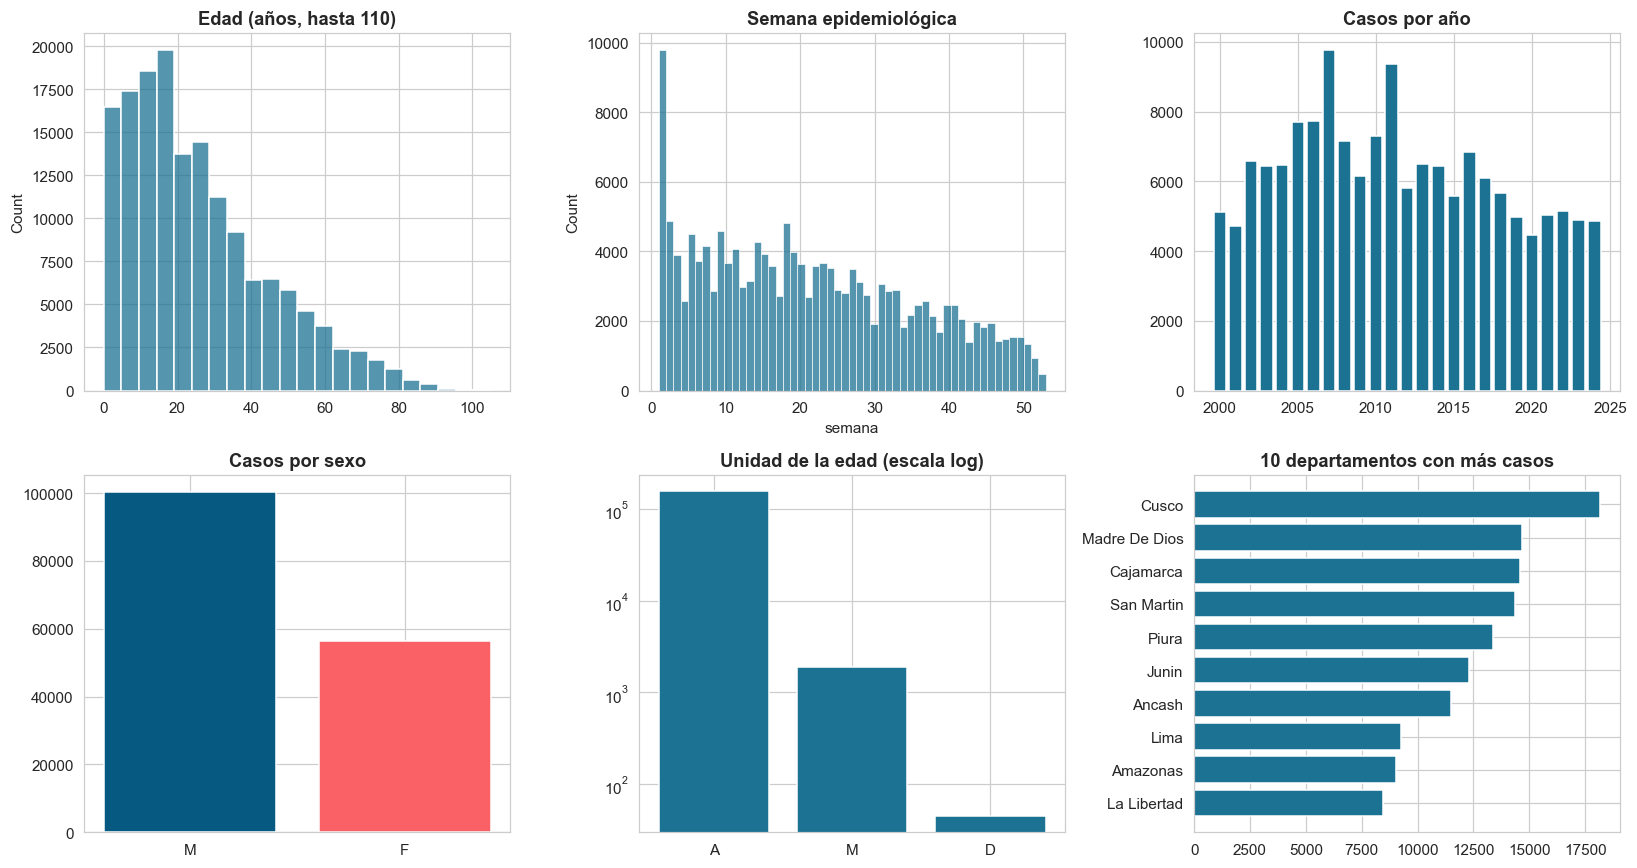

In [5]:
factor = {"A": 1, "M": 1 / 12, "D": 1 / 365}
edad_anios_raw = df["edad"] * df["tipo_edad"].map(factor)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

sns.histplot(edad_anios_raw[edad_anios_raw <= 110], bins=22, color=C1, ax=axes[0])
axes[0].set_title("Edad (años, hasta 110)")

sns.histplot(df["semana"], bins=53, color=C1, ax=axes[1])
axes[1].set_title("Semana epidemiológica")

por_anio = df["ano"].value_counts().sort_index()
axes[2].bar(por_anio.index, por_anio.values, color=C1)
axes[2].set_title("Casos por año")

sx = df["sexo"].value_counts()
axes[3].bar(sx.index, sx.values, color=[C2, ROJO])
axes[3].set_title("Casos por sexo")

te = df["tipo_edad"].value_counts()
axes[4].bar(te.index, te.values, color=C1)
axes[4].set_yscale("log")
axes[4].set_title("Unidad de la edad (escala log)")

dep = df["departamento"].value_counts().head(10)
axes[5].barh(dep.index.str.title()[::-1], dep.values[::-1], color=C1)
axes[5].set_title("10 departamentos con más casos")

plt.tight_layout()
guardar("distribucion_casos")
plt.show()

La edad se concentra en adultos jóvenes (mediana de 21 años) con una cola larga hacia edades mayores, y hay una mayoría de varones. La semana epidemiológica muestra dos rasgos: un pico en la semana 1 y un descenso gradual a lo largo del año.

## 3. Calidad de los datos a nivel caso

### 3.1 Faltantes por columna y por fila

In [6]:
# Por columna
missing_df[missing_df["Faltantes"] > 0].sort_values("Porcentaje (%)", ascending=False)

,Columna,Faltantes,Porcentaje (%)
10,localcod,50513,32.21
3,localidad,8837,5.64
8,diresa,6,0.00


In [7]:
# Por fila: cuántos campos faltan en cada registro
missing_by_row = df.isnull().sum(axis=1)
fila_stats_df = pd.DataFrame({
    "Num Faltantes": missing_by_row.value_counts().sort_index().index,
    "Conteo Filas": missing_by_row.value_counts().sort_index().values,
})
fila_stats_df["% de filas"] = (fila_stats_df["Conteo Filas"] / len(df) * 100).round(2)
fila_stats_df

,Num Faltantes,Conteo Filas,% de filas
0,0,103611,66.07
1,1,47066,30.01
2,2,6136,3.91
3,3,6,0.00


### 3.2 Conversiones sin pérdida de información

Solo se corrige el formato para poder explorar. Los faltantes y los valores imposibles se dejan como están.

In [8]:
df_clean = df.copy()

# 1) ubigeo a 6 dígitos y control de consistencia
df_clean["ubigeo"] = df_clean["ubigeo"].astype(str).str.zfill(6)
chk = df_clean.groupby("ubigeo").agg(d=("distrito", "nunique"), p=("provincia", "nunique"))
print("Ubigeos con más de un distrito o provincia:", int(((chk["d"] > 1) | (chk["p"] > 1)).sum()))

# 2) edad en años (los valores imposibles se marcan como nulos, no se imputan)
df_clean["edad_anios"] = df_clean["edad"] * df_clean["tipo_edad"].map(factor)
errores_edad = df_clean["edad_anios"] > 110
print(f"Edades imposibles (> 110 años): {errores_edad.sum()}  -> se marcan como nulas")
df_clean.loc[errores_edad, "edad_anios"] = np.nan

# 3) fecha aproximada: 1 de enero + 7·(semana − 1)
df_clean["fecha"] = pd.to_datetime(df_clean["ano"].astype(str) + "-01-01") + pd.to_timedelta((df_clean["semana"] - 1) * 7, unit="D")
df_clean["periodo"] = df_clean["fecha"].dt.to_period("M")
df_clean["mes"] = df_clean["fecha"].dt.month

Ubigeos con más de un distrito o provincia: 0
Edades imposibles (> 110 años): 4  -> se marcan como nulas


### 3.3 Resumen de hallazgos de calidad

| Columna | Hallazgo | Observación |
|---|---|---|
| `localcod` | 32 % de faltantes | Código del centro poblado; no se usará para modelar |
| `localidad` | 5,6 % de faltantes | Descriptiva; no se usará para modelar |
| `diresa` | 6 faltantes | Todos del mismo distrito (Kumpirushiato, ubigeo 080915) |
| `edad` | 4 valores imposibles y unidades mezcladas | Errores de captura |
| `ubigeo` | Sin el cero inicial en 56 057 registros | Se corrigió el formato |
| Duplicados | 1 119 filas idénticas | Pueden ser casos distintos con los mismos atributos |
| `semana` 53 | 481 registros | Depende del calendario epidemiológico de cada año |

## 4. Exploración temporal y espacial

En una serie de tiempo lo primero es entender tendencia, estacionalidad, geografía y cuánta información hay a escala fina, porque eso determina cómo se construye la tabla de modelado.

### 4.1 Evolución anual

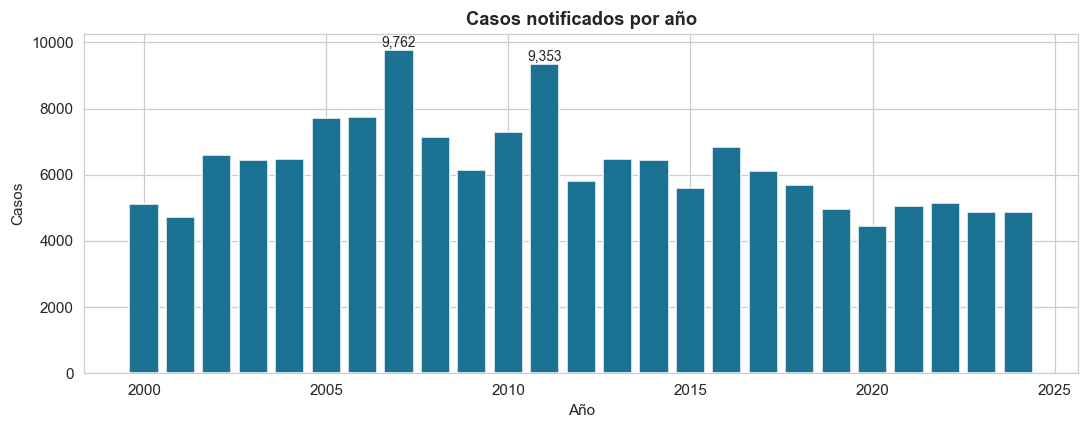

Mínimo: 2020 (4,452)   Máximo: 2007 (9,762)


In [9]:
casos_anio = df_clean.groupby("ano").size()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(casos_anio.index, casos_anio.values, color=C1)
ax.set_title("Casos notificados por año")
ax.set_xlabel("Año")
ax.set_ylabel("Casos")
for a in (2007, 2011):
    ax.annotate(f"{casos_anio[a]:,}", (a, casos_anio[a]), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
guardar("casos_por_anio")
plt.show()
print(f"Mínimo: {casos_anio.idxmin()} ({casos_anio.min():,})   Máximo: {casos_anio.idxmax()} ({casos_anio.max():,})")

La serie tiene dos picos (2007 con 9 762 casos y 2011 con 9 353), baja de forma gradual hasta 2019–2020 y desde entonces se mantiene en un nivel bajo y estable, entre 4 500 y 5 100 casos al año. La caída empieza antes de la pandemia, así que el COVID-19 no la explica por completo. Con estos datos no se puede distinguir si refleja menor transmisión o menor notificación.

### 4.2 Casos por semana epidemiológica

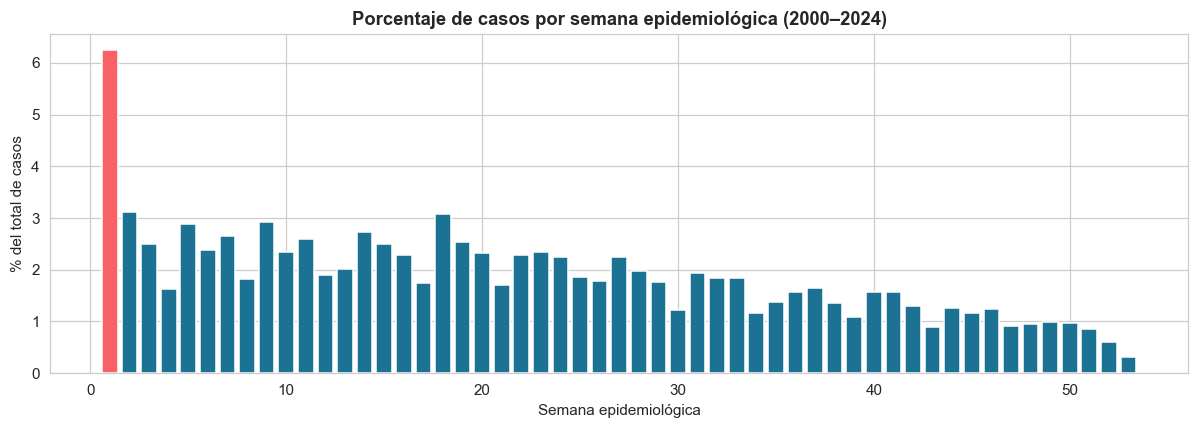

Semana 1: 6.2% de los casos; semanas 2–4: 2.4% en promedio (2.6 veces más)

% de los casos de cada año que cae en la semana 1:
ano
2000    4.90
2001    5.10
2002    3.60
2003    3.80
2004    5.30
2005    5.40
2006    7.30
2007    5.80
2008    6.20
2009    4.90
2010    5.90
2011    5.10
2012    7.50
2013    5.20
2014    5.00
2015    5.40
2016    6.10
2017    9.00
2018    7.90
2019    8.90
2020    5.80
2021    7.10
2022    8.50
2023    8.70
2024   11.40


In [26]:
por_semana = df_clean.groupby("semana").size()
prop_sem = por_semana / por_semana.sum() * 100

fig, ax = plt.subplots(figsize=(11, 4))
colores = [ROJO if s == 1 else C1 for s in por_semana.index]
ax.bar(por_semana.index, prop_sem.values, color=colores)
ax.set_title("Porcentaje de casos por semana epidemiológica (2000–2024)")
ax.set_xlabel("Semana epidemiológica")
ax.set_ylabel("% del total de casos")
plt.tight_layout()
guardar("casos_por_semana")
plt.show()

vecinas = prop_sem.loc[2:4].mean()
print(f"Semana 1: {prop_sem[1]:.1f}% de los casos; semanas 2–4: {vecinas:.1f}% en promedio ({prop_sem[1] / vecinas:.1f} veces más)")

sem1_anio = df_clean.groupby("ano")["semana"].apply(lambda s: (s == 1).mean() * 100)
print("\n% de los casos de cada año que cae en la semana 1:")
print(sem1_anio.round(1).to_string())

Anomalía en la semana 1. Concentra el 6,2 % de los casos, unas 2,6 veces el nivel de las semanas vecinas, y el exceso se repite todos los años. Su peso además crece con el tiempo (entre 4 % y 5 % a inicios de los 2000, 11 % en 2024). Este patrón es típico de un artefacto de registro, por ejemplo casos sin fecha de inicio precisa que se asignan a la primera semana, y no de un fenómeno biológico. No se corrige porque no hay forma de saber cuáles casos son los desplazados, pero infla enero en cualquier agregación mensual.

### 4.3 Estacionalidad

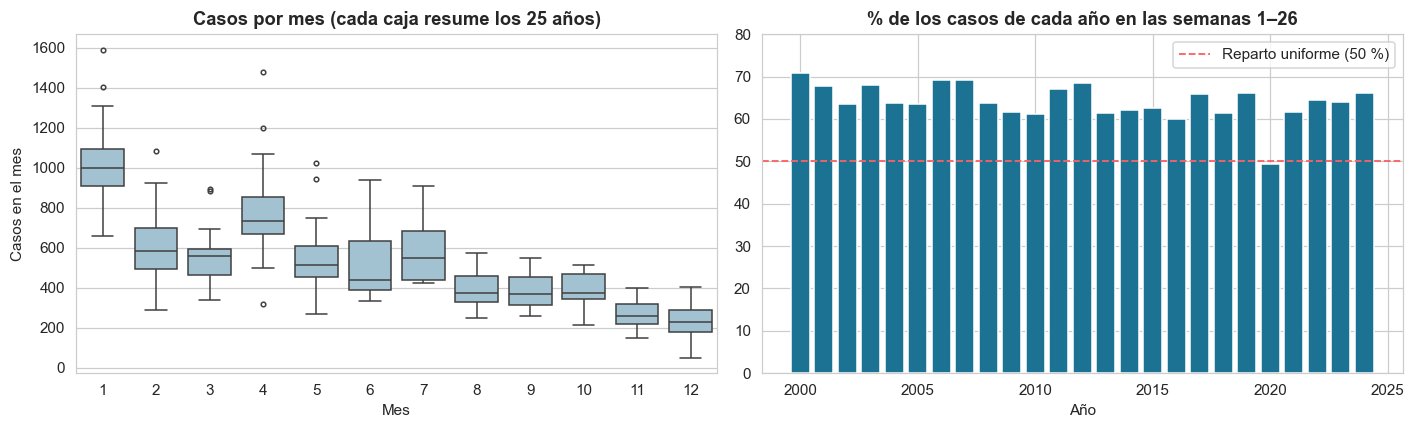

Años con más del 55 % de los casos en el primer semestre: 24 de 25
Excepción: 2020 (49 %)


In [11]:
h1 = df_clean.assign(h1=df_clean["semana"] <= 26).groupby("ano")["h1"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

por_mes = df_clean.groupby(["ano", "mes"]).size().unstack(fill_value=0)
sns.boxplot(data=por_mes, color=C3, fliersize=3, ax=axes[0])
axes[0].set_title("Casos por mes (cada caja resume los 25 años)")
axes[0].set_xlabel("Mes")
axes[0].set_ylabel("Casos en el mes")

axes[1].bar(h1.index, h1.values, color=C1)
axes[1].axhline(50, color=ROJO, ls="--", lw=1.2, label="Reparto uniforme (50 %)")
axes[1].set_ylim(0, 80)
axes[1].set_title("% de los casos de cada año en las semanas 1–26")
axes[1].set_xlabel("Año")
axes[1].legend()

plt.tight_layout()
guardar("estacionalidad")
plt.show()

print(f"Años con más del 55 % de los casos en el primer semestre: {(h1 > 55).sum()} de {len(h1)}")
print(f"Excepción: {h1.idxmin()} ({h1.min():.0f} %)")

Hay una **estacionalidad marcada y estable**: en 24 de los 25 años, entre el 60 % y el 71 % de los casos se notifica en el primer semestre, con un repunte secundario en abril, y noviembre y diciembre son los meses con menos casos. La única excepción es 2020, el año de la pandemia. Parte del exceso de enero viene de la semana 1, pero el descenso a lo largo del año persiste sin ella.

Esta señal es del **dato notificado**, no necesariamente del ciclo de transmisión: podría reflejar tanto el clima como rutinas de notificación, y esa distinción es una limitación a declarar en el reporte.

### 4.4 Concentración geográfica

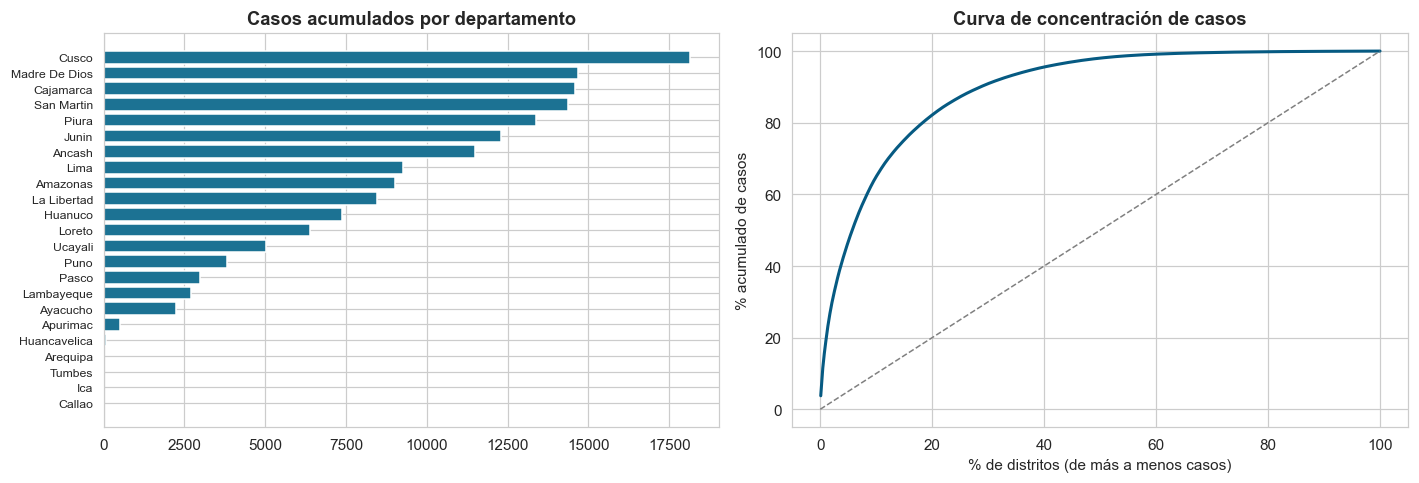

Los 5 departamentos con más casos concentran 47.9% del total.
El 5% de distritos (55) concentra 46.8% de los casos
El 10% de distritos (110) concentra 65.0% de los casos
El 20% de distritos (220) concentra 82.2% de los casos


,casos,departamento,provincia,distrito,casos/año
ubigeo,,,,,
080902,5925,CUSCO,LA CONVENCION,ECHARATE,237.00
170101,3187,MADRE DE DIOS,TAMBOPATA,TAMBOPATA,127.50
200304,3114,PIURA,HUANCABAMBA,HUARMACA,124.60
170103,3114,MADRE DE DIOS,TAMBOPATA,LAS PIEDRAS,124.60
120606,2700,JUNIN,SATIPO,PANGOA,108.00
080906,2224,CUSCO,LA CONVENCION,QUELLOUNO,89.00
200202,2216,PIURA,AYABACA,FRIAS,88.60
080408,1950,CUSCO,CALCA,YANATILE,78.00
200302,1888,PIURA,HUANCABAMBA,CANCHAQUE,75.50


In [27]:
por_ubigeo = df_clean.groupby("ubigeo").size().sort_values(ascending=False)
n = len(por_ubigeo)
acum = por_ubigeo.cumsum() / por_ubigeo.sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

dep = df_clean["departamento"].value_counts()
axes[0].barh(dep.index.str.title()[::-1], dep.values[::-1], color=C1)
axes[0].set_title("Casos acumulados por departamento")
axes[0].tick_params(axis="y", labelsize=8)

axes[1].plot(np.arange(1, n + 1) / n * 100, acum.values * 100, color=C2, lw=2)
axes[1].plot([0, 100], [0, 100], "--", color="gray", lw=1)
axes[1].set_xlabel("% de distritos (de más a menos casos)")
axes[1].set_ylabel("% acumulado de casos")
axes[1].set_title("Curva de concentración de casos")

plt.tight_layout()
guardar("geografia")
plt.show()

print(f"Los 5 departamentos con más casos concentran {dep.head(5).sum() / dep.sum():.1%} del total.")
for p in (0.05, 0.10, 0.20):
    k = int(round(n * p))
    print(f"El {p:.0%} de distritos ({k}) concentra {por_ubigeo.head(k).sum() / por_ubigeo.sum():.1%} de los casos")

nombres = df_clean.drop_duplicates("ubigeo").set_index("ubigeo")[["departamento", "provincia", "distrito"]]
top = por_ubigeo.head(10).to_frame("casos").join(nombres)
top["casos/año"] = (top["casos"] / df_clean["ano"].nunique()).round(1)
top

### 4.5 Dispersión a escala distrital

Para predecir hay que agregar los casos por distrito y periodo. La pregunta es cuántas de esas celdas tienen información, porque decide la resolución temporal y a cuántos distritos se puede modelar.

In [13]:
n_ubigeos = df_clean["ubigeo"].nunique()
celdas_posibles = n_ubigeos * df_clean["ano"].nunique() * 52
celdas = df_clean.groupby(["ubigeo", "ano", "semana"]).size()
print(f"Distritos con al menos un caso: {n_ubigeos:,}")
print(f"Celdas distrito-semana posibles: {celdas_posibles:,}")
print(f"Celdas con al menos un caso:     {len(celdas):,}  ({len(celdas) / celdas_posibles:.1%})")

tot = df_clean.groupby("ubigeo").size()
anios_activos = df_clean.groupby("ubigeo")["ano"].nunique()
filas = []
for umbral in (1, 10, 50, 100, 250, 500):
    sel = tot[tot >= umbral].index
    filas.append({
        "casos mínimos": umbral, "distritos": len(sel),
        "% distritos": len(sel) / len(tot) * 100,
        "% de casos cubiertos": tot[sel].sum() / tot.sum() * 100,
        "años activos (mediana)": anios_activos[sel].median(),
    })
pd.DataFrame(filas).set_index("casos mínimos")

Distritos con al menos un caso: 1,100
Celdas distrito-semana posibles: 1,430,000
Celdas con al menos un caso:     96,762  (6.8%)


,distritos,% distritos,% de casos cubiertos,años activos (mediana)
casos mínimos,,,,
1,1100,100.00,100.00,11.00
10,659,59.91,99.14,20.00
50,435,39.55,95.40,23.00
100,314,28.55,89.94,24.00
250,150,13.64,72.85,25.00
500,82,7.45,56.95,25.00


A escala distrito-semana solo el 6,8 % de las celdas tiene casos, así que modelar semana a semana produciría series de ceros con picos esporádicos. Se opta por **agregar a mes** y **restringir a distritos con actividad suficiente**. El umbral de 50 casos acumulados deja 435 distritos que cubren el 95 % de los casos y están activos una mediana de 23 de los 25 años.

### 4.6 Memoria temporal (autocorrelación)

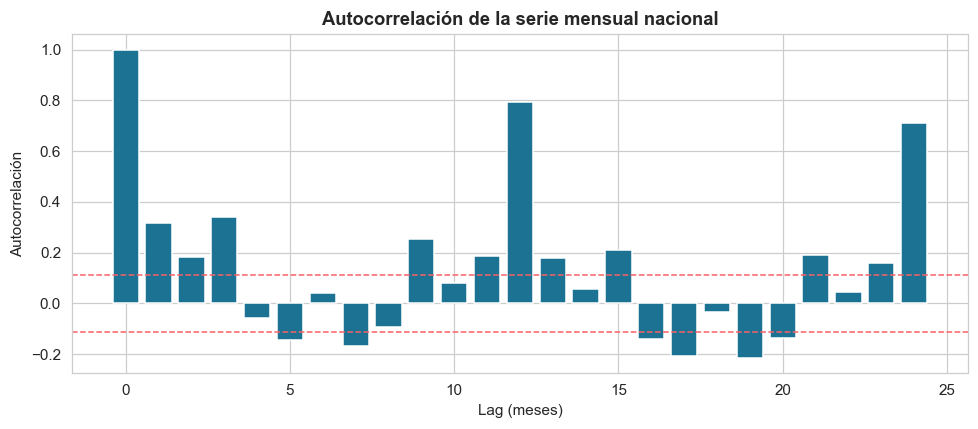

Con semana 1  · lag 1, 3, 6, 12: [0.32 0.34 0.04 0.79]
Sin semana 1  · lag 1, 3, 6, 12: [ 0.6   0.38 -0.06  0.73]


In [14]:
mensual = df_clean.groupby("periodo").size()
mensual.index = mensual.index.to_timestamp()
mensual = mensual.asfreq("MS", fill_value=0)
mens_sin1 = (df_clean[df_clean["semana"] != 1].groupby("periodo").size()
             .rename(lambda p: p.to_timestamp()).reindex(mensual.index, fill_value=0))

n_lags = 24
ac_nac = acf(mensual.values, nlags=n_lags, fft=True)
ac_sin1 = acf(mens_sin1.values, nlags=n_lags, fft=True)
banda = 1.96 / np.sqrt(len(mensual))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(n_lags + 1), ac_nac, color=C1)
ax.axhline(banda, color=ROJO, ls="--", lw=1)
ax.axhline(-banda, color=ROJO, ls="--", lw=1)
ax.set_title("Autocorrelación de la serie mensual nacional")
ax.set_xlabel("Lag (meses)")
ax.set_ylabel("Autocorrelación")
plt.tight_layout()
guardar("autocorrelacion")
plt.show()

print("Con semana 1  · lag 1, 3, 6, 12:", np.round(ac_nac[[1, 3, 6, 12]], 2))
print("Sin semana 1  · lag 1, 3, 6, 12:", np.round(ac_sin1[[1, 3, 6, 12]], 2))

El resultado más claro es el **pico en el lag 12** (0,79, y todavía 0,73 sin la semana 1): la serie se parece mucho a sí misma un año después. El lag 6 es casi nulo, coherente con un ciclo anual de un solo máximo. La correlación con el mes anterior es moderada (0,32; sube a 0,60 al quitar la semana 1, lo que indica que esa anomalía le mete ruido al lag 1).

De aquí salen los rezagados que se usarán como variables: **lags 1, 2, 3 y 12**.

## 5. Construcción de la tabla de modelado

Se agrega a **distrito × mes** para los distritos con al menos 50 casos acumulados, y se construyen las variables a partir de datos **anteriores** al mes que se quiere predecir. Cada variable se calcula dentro de su distrito (`groupby`), de modo que un distrito nunca recibe información de otro.

| Variable | Descripción |
|---|---|
| `lag1`, `lag2`, `lag3`, `lag12` | Casos del distrito 1, 2, 3 y 12 meses antes |
| `media3` | Promedio de los 3 meses previos |
| `mes_sin`, `mes_cos` | Mes del año codificado de forma cíclica (diciembre queda junto a enero) |
| `casos` | **Objetivo de regresión:** casos del mes |
| `alerta` | **Objetivo de clasificación** (definición provisional, abajo) |

**Partición temporal.** Entrenamiento: hasta diciembre de 2018. Prueba: desde 2019. Los umbrales y cualquier estadístico que se calcule de los datos usan solo el periodo de entrenamiento.

In [15]:
UMBRAL_CASOS = 50
TRAIN_END = "2018-12-31"
FEATURES = ["lag1", "lag2", "lag3", "lag12", "media3", "mes_sin", "mes_cos"]
CONTEOS = ["lag1", "lag2", "lag3", "lag12", "media3"]

activos = tot[tot >= UMBRAL_CASOS].index
meses = pd.period_range(df_clean["periodo"].min(), df_clean["periodo"].max(), freq="M")

panel = (df_clean[df_clean["ubigeo"].isin(activos)]
         .groupby(["ubigeo", "periodo"]).size()
         .unstack("ubigeo")
         .reindex(meses, fill_value=0)
         .fillna(0).astype(int)
         .stack().rename("casos").reset_index())
panel.columns = ["periodo", "ubigeo", "casos"]
panel["fecha_mes"] = panel["periodo"].dt.to_timestamp()
panel = panel.merge(nombres.reset_index(), on="ubigeo", how="left")
panel = panel.sort_values(["ubigeo", "fecha_mes"]).reset_index(drop=True)

# Variables rezagadas, calculadas dentro de cada distrito
g = panel.groupby("ubigeo")["casos"]
for k in (1, 2, 3, 12):
    panel[f"lag{k}"] = g.shift(k)
panel["media3"] = g.transform(lambda s: s.shift(1).rolling(3).mean())

# Mes cíclico
mes = panel["fecha_mes"].dt.month
panel["mes_sin"] = np.sin(2 * np.pi * mes / 12)
panel["mes_cos"] = np.cos(2 * np.pi * mes / 12)

# Partición temporal
panel["es_train"] = panel["fecha_mes"] <= TRAIN_END
train = panel["es_train"]

print(f"Tabla de modelado: {len(panel):,} filas · {panel['ubigeo'].nunique()} distritos · {panel['fecha_mes'].nunique()} meses")
print(f"Entrenamiento: {train.sum():,} filas ({panel.loc[train, 'fecha_mes'].min():%Y-%m} a {panel.loc[train, 'fecha_mes'].max():%Y-%m})")
print(f"Prueba:        {(~train).sum():,} filas ({panel.loc[~train, 'fecha_mes'].min():%Y-%m} a {panel.loc[~train, 'fecha_mes'].max():%Y-%m})")
panel[["ubigeo", "distrito", "fecha_mes", "casos"] + FEATURES].head(15)

Tabla de modelado: 130,500 filas · 435 distritos · 300 meses
Entrenamiento: 99,180 filas (2000-01 a 2018-12)
Prueba:        31,320 filas (2019-01 a 2024-12)


,ubigeo,distrito,fecha_mes,casos,lag1,lag2,lag3,lag12,media3,mes_sin,mes_cos
0,010101,CHACHAPOYAS,2000-01-01,0,NaN,NaN,NaN,NaN,NaN,0.50,0.87
1,010101,CHACHAPOYAS,2000-02-01,0,0.00,NaN,NaN,NaN,NaN,0.87,0.50
2,010101,CHACHAPOYAS,2000-03-01,1,0.00,0.00,NaN,NaN,NaN,1.00,0.00
3,010101,CHACHAPOYAS,2000-04-01,0,1.00,0.00,0.00,NaN,0.33,0.87,-0.50
4,010101,CHACHAPOYAS,2000-05-01,0,0.00,1.00,0.00,NaN,0.33,0.50,-0.87
5,010101,CHACHAPOYAS,2000-06-01,4,0.00,0.00,1.00,NaN,0.33,0.00,-1.00
6,010101,CHACHAPOYAS,2000-07-01,0,4.00,0.00,0.00,NaN,1.33,-0.50,-0.87
7,010101,CHACHAPOYAS,2000-08-01,0,0.00,4.00,0.00,NaN,1.33,-0.87,-0.50
8,010101,CHACHAPOYAS,2000-09-01,2,0.00,0.00,4.00,NaN,1.33,-1.00,-0.00
9,010101,CHACHAPOYAS,2000-10-01,2,2.00,0.00,0.00,NaN,0.67,-0.87,0.50


### Variable de alerta (definición provisional)

El dataset no trae una variable de brote. Para poder explorar el desbalance de clases se define una **alerta distrital**: el mes en que los casos superan **la media del distrito más dos desviaciones estándar**, calculadas solo con los meses de entrenamiento. Es una versión simple de un canal endémico.

Esta definición es provisional, no es un umbral oficial del MINSA.

In [16]:
est = panel.loc[train].groupby("ubigeo")["casos"].agg(["mean", "std"])
umbral_d = est["mean"] + 2 * est["std"]
panel["umbral"] = panel["ubigeo"].map(umbral_d)
panel["alerta"] = (panel["casos"] > panel["umbral"]).astype(int)

print(f"Meses en alerta · entrenamiento: {panel.loc[train, 'alerta'].mean():.2%}   prueba: {panel.loc[~train, 'alerta'].mean():.2%}")

Meses en alerta · entrenamiento: 4.69%   prueba: 3.43%


## 6. Exploración de problemas en la tabla de modelado

### 6.1 Valores faltantes

In [17]:
missing = panel[FEATURES].isnull().sum()
missing_df = pd.DataFrame({
    "Columna": missing.index,
    "Faltantes": missing.values,
    "Porcentaje (%)": (missing / len(panel) * 100).values,
})
missing_df.sort_values("Faltantes", ascending=False)

,Columna,Faltantes,Porcentaje (%)
3,lag12,5220,4.00
2,lag3,1305,1.00
4,media3,1305,1.00
1,lag2,870,0.67
0,lag1,435,0.33
5,mes_sin,0,0.00
6,mes_cos,0,0.00


In [18]:
# Por fila
missing_by_row = panel[FEATURES].isnull().sum(axis=1)
pd.DataFrame({
    "Num Faltantes": missing_by_row.value_counts().sort_index().index,
    "Conteo Filas": missing_by_row.value_counts().sort_index().values,
})

,Num Faltantes,Conteo Filas
0,0,125280
1,1,3915
2,3,435
3,4,435
4,5,435


In [19]:
# ¿Dónde caen los faltantes? Se espera que solo en los primeros meses de cada distrito
primer_mes = panel["fecha_mes"].min()
faltan = panel[missing_by_row > 0]
print(f"Filas con algún faltante: {len(faltan):,} ({len(faltan) / len(panel):.1%})")
print(f"Rango de fechas de esas filas: {faltan['fecha_mes'].min():%Y-%m} a {faltan['fecha_mes'].max():%Y-%m}")
print(f"Distritos afectados: {faltan['ubigeo'].nunique()} de {panel['ubigeo'].nunique()}")

Filas con algún faltante: 5,220 (4.0%)
Rango de fechas de esas filas: 2000-01 a 2000-12
Distritos afectados: 435 de 435


Estos faltantes son de un tipo distinto a los revisados en la sección 3, no son datos perdidos sino ausencia de historia. Un distrito no puede tener `lag12` en sus primeros 12 meses porque no existe un valor 12 meses antes del inicio de la serie. Aparecen siempre en el mismo tramo (enero a diciembre de 2000) y en todos los distritos por igual. Esto influirá en cómo se traten más adelante.

### 6.2 Desbalance de clases

In [20]:
class_dist = panel.loc[train, "alerta"].value_counts().sort_index()
class_df = pd.DataFrame({
    "Clase": class_dist.index,
    "Cantidad": class_dist.values,
    "Porcentaje (%)": (class_dist.values / class_dist.sum() * 100).round(1),
})
ratio = class_dist.max() / class_dist.min()
print(f"Ratio de desbalance (entrenamiento): {ratio:.2f}:1")
class_df

Ratio de desbalance (entrenamiento): 20.32:1


,Clase,Cantidad,Porcentaje (%)
0,0,94528,95.30
1,1,4652,4.70


### 6.3 Escalas diferentes

In [21]:
scales_df = pd.DataFrame({
    "Característica": FEATURES,
    "Mín": panel[FEATURES].min().values,
    "Máx": panel[FEATURES].max().values,
    "Rango": (panel[FEATURES].max() - panel[FEATURES].min()).values,
}).round(2).sort_values("Rango", ascending=False)
scales_df

,Característica,Mín,Máx,Rango
0,lag1,0.00,125.00,125.00
1,lag2,0.00,125.00,125.00
2,lag3,0.00,125.00,125.00
3,lag12,0.00,125.00,125.00
4,media3,0.00,78.33,78.33
5,mes_sin,-1.00,1.00,2.00
6,mes_cos,-1.00,1.00,2.00


### 6.4 Distribución

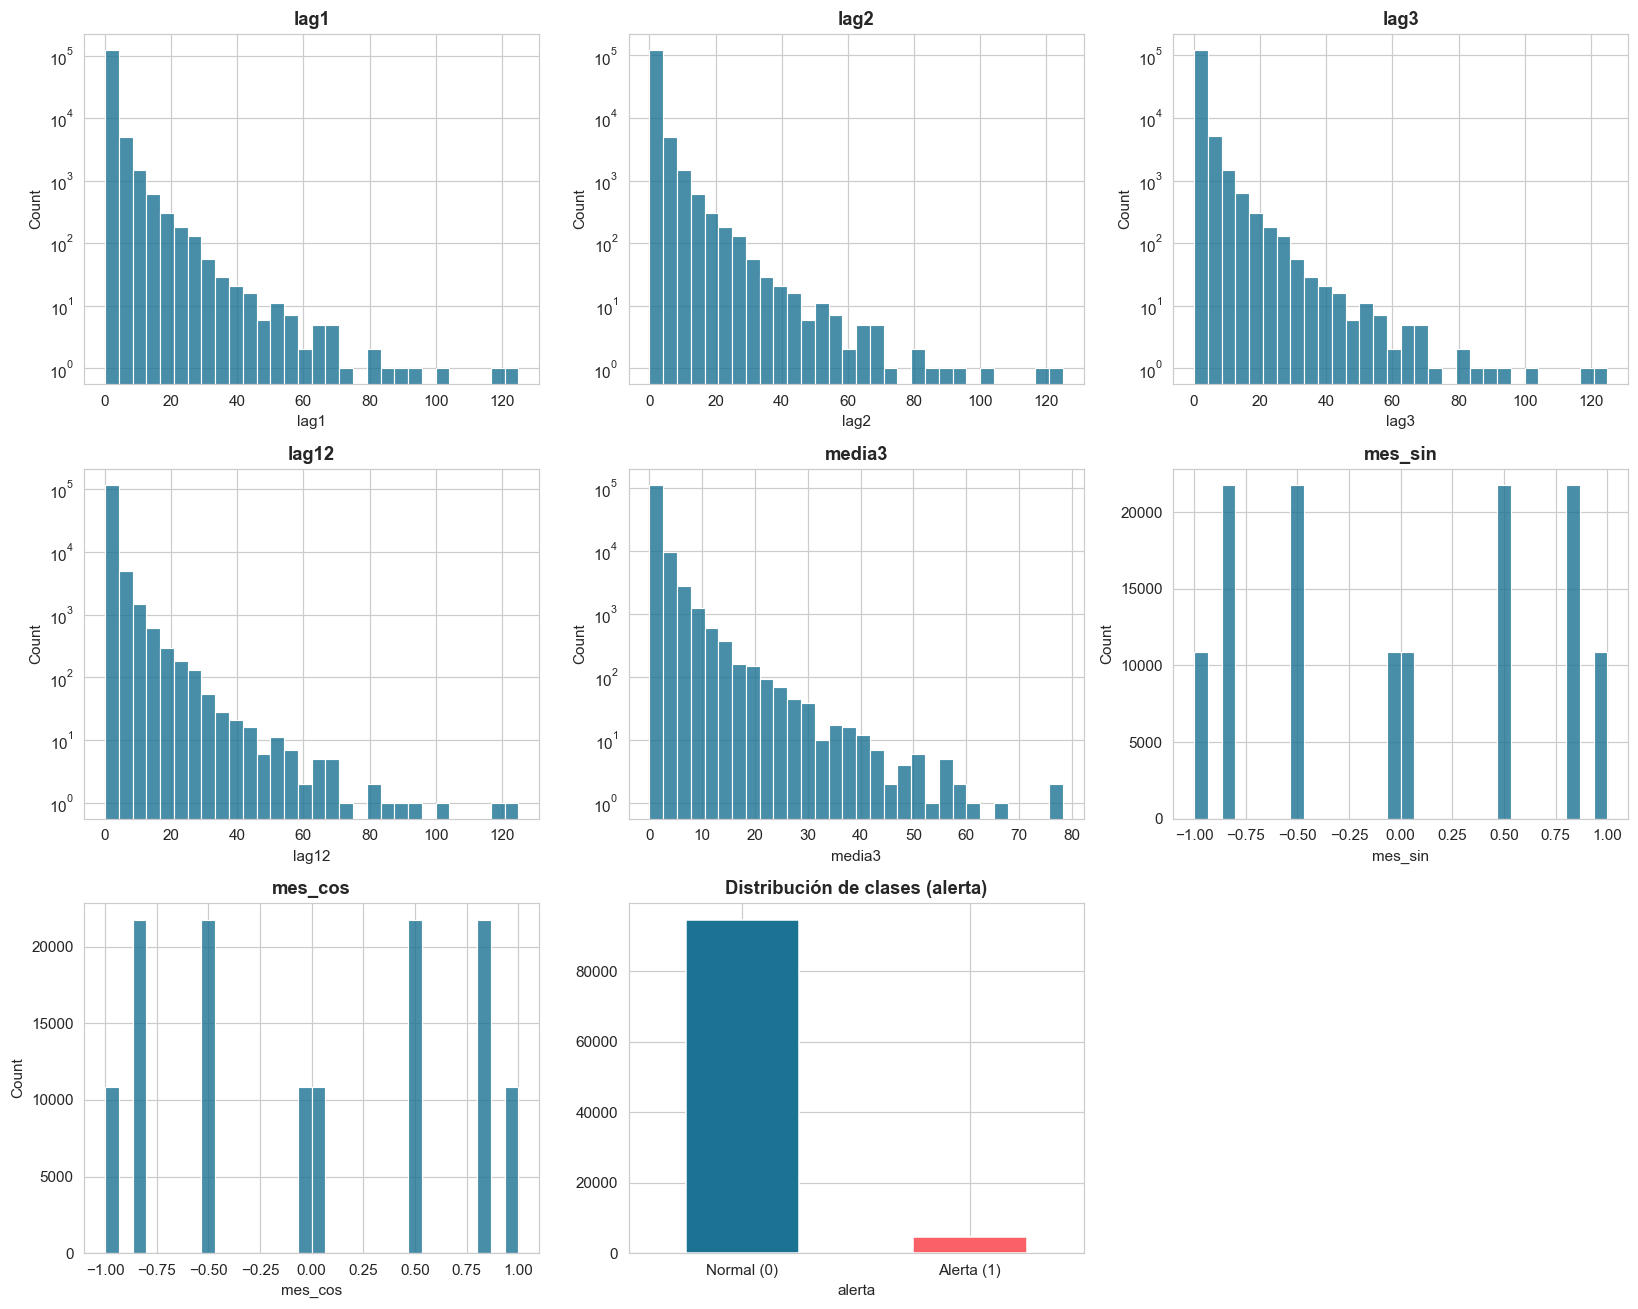

Asimetría (skew) de las variables de conteo:
lag1     8.70
lag2     8.70
lag3     8.70
lag12    8.70
media3   7.20

Proporción de ceros en 'casos': 60.9%


In [22]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(FEATURES):
    sns.histplot(data=panel, x=col, ax=axes[i], bins=30, color=C1, alpha=0.8)
    axes[i].set_title(col, fontweight="bold")
    if col in CONTEOS:
        axes[i].set_yscale("log")

panel.loc[train, "alerta"].value_counts().sort_index().plot(kind="bar", ax=axes[7], color=[C1, ROJO])
axes[7].set_title("Distribución de clases (alerta)", fontweight="bold")
axes[7].set_xticklabels(["Normal (0)", "Alerta (1)"], rotation=0)
axes[8].axis("off")

plt.tight_layout()
guardar("distribucion_modelado")
plt.show()

print("Asimetría (skew) de las variables de conteo:")
print(panel[CONTEOS].skew().round(1).to_string())
print(f"\nProporción de ceros en 'casos': {(panel['casos'] == 0).mean():.1%}")


Las cuatro variables de conteo comparten la misma forma: **muchos ceros y una cola muy larga**. El 60,9 % de los meses por distrito tiene cero casos, la asimetría ronda 8,7 y el máximo llega a 125 casos en un solo mes. Por eso los histogramas llevan escala logarítmica en el eje vertical: en escala lineal solo se vería la barra del cero. `mes_sin` y `mes_cos` no tienen este problema, porque son cíclicas y están acotadas entre −1 y 1.

La media (1,25) no describe un mes típico, ya que la mediana es 0. Ese hecho pesa en la detección de outliers (§7) y en el preprocesamiento posterior.


## 7. Detección de outliers

Solo se detectan y se describen. No se recorta ni se transforma nada.

### 7.1 A nivel de caso: edad

In [23]:
e = df_clean["edad_anios"].dropna()

z_e = np.abs(stats.zscore(e))
Q1, Q3 = e.quantile(0.25), e.quantile(0.75)
IQR = Q3 - Q1
lim_inf, lim_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

print(f"Z-score > 3:  {(z_e > 3).sum():,} casos ({(z_e > 3).mean():.2%})")
print(f"IQR [{lim_inf:.1f}, {lim_sup:.1f}]: {((e < lim_inf) | (e > lim_sup)).sum():,} casos ({((e < lim_inf) | (e > lim_sup)).mean():.2%})")
print(f"Edad máxima: {e.max():.0f} años")

Z-score > 3:  913 casos (0.58%)
IQR [-28.0, 76.0]: 2,331 casos (1.49%)
Edad máxima: 105 años


Descartados los cuatro errores de captura, lo que marcan ambos métodos son personas de edad avanzada reales, no errores. Aquí la regla de dominio (nadie supera los 110 años) fue más fiable que el criterio estadístico.

### 7.2 En la tabla de modelado: z-score e IQR

Se calculan sobre las filas de entrenamiento con historia completa. Es solo para medir: no se descarta nada de la tabla.

In [24]:
panel_m = panel.dropna(subset=FEATURES)   # solo para medir
train_m = panel_m["es_train"]
Xc = panel_m.loc[train_m, FEATURES]


# Z-score
z_scores = pd.DataFrame(np.abs(stats.zscore(Xc)), columns=FEATURES, index=Xc.index)
outliers_z = z_scores > 3

# IQR
Q1 = Xc.quantile(0.25)
Q3 = Xc.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers_iqr = (Xc < lower_bound) | (Xc > upper_bound)

outliers_summary = pd.DataFrame({
    "Columna": FEATURES,
    "Z-score > 3": outliers_z.sum().values,
    "Z-score (%)": (outliers_z.mean().values * 100).round(2),
    "IQR": outliers_iqr.sum().values,
    "IQR (%)": (outliers_iqr.mean().values * 100).round(2),
    "Q1": Q1.values.round(2), "Q3": Q3.values.round(2),
    "Límite sup. IQR": upper_bound.values.round(2),
})
outliers_summary.sort_values("IQR", ascending=False)

,Columna,Z-score > 3,Z-score (%),IQR,IQR (%),Q1,Q3,Límite sup. IQR
0,lag1,1646,1.75,13165,14.01,0.00,1.00,2.50
1,lag2,1645,1.75,13154,14.00,0.00,1.00,2.50
3,lag12,1652,1.76,13131,13.98,0.00,1.00,2.50
2,lag3,1641,1.75,13122,13.97,0.00,1.00,2.50
4,media3,1655,1.76,8984,9.56,0.00,1.33,3.33
5,mes_sin,0,0.00,0,0.00,-0.59,0.59,2.37
6,mes_cos,0,0.00,0,0.00,-0.59,0.59,2.37


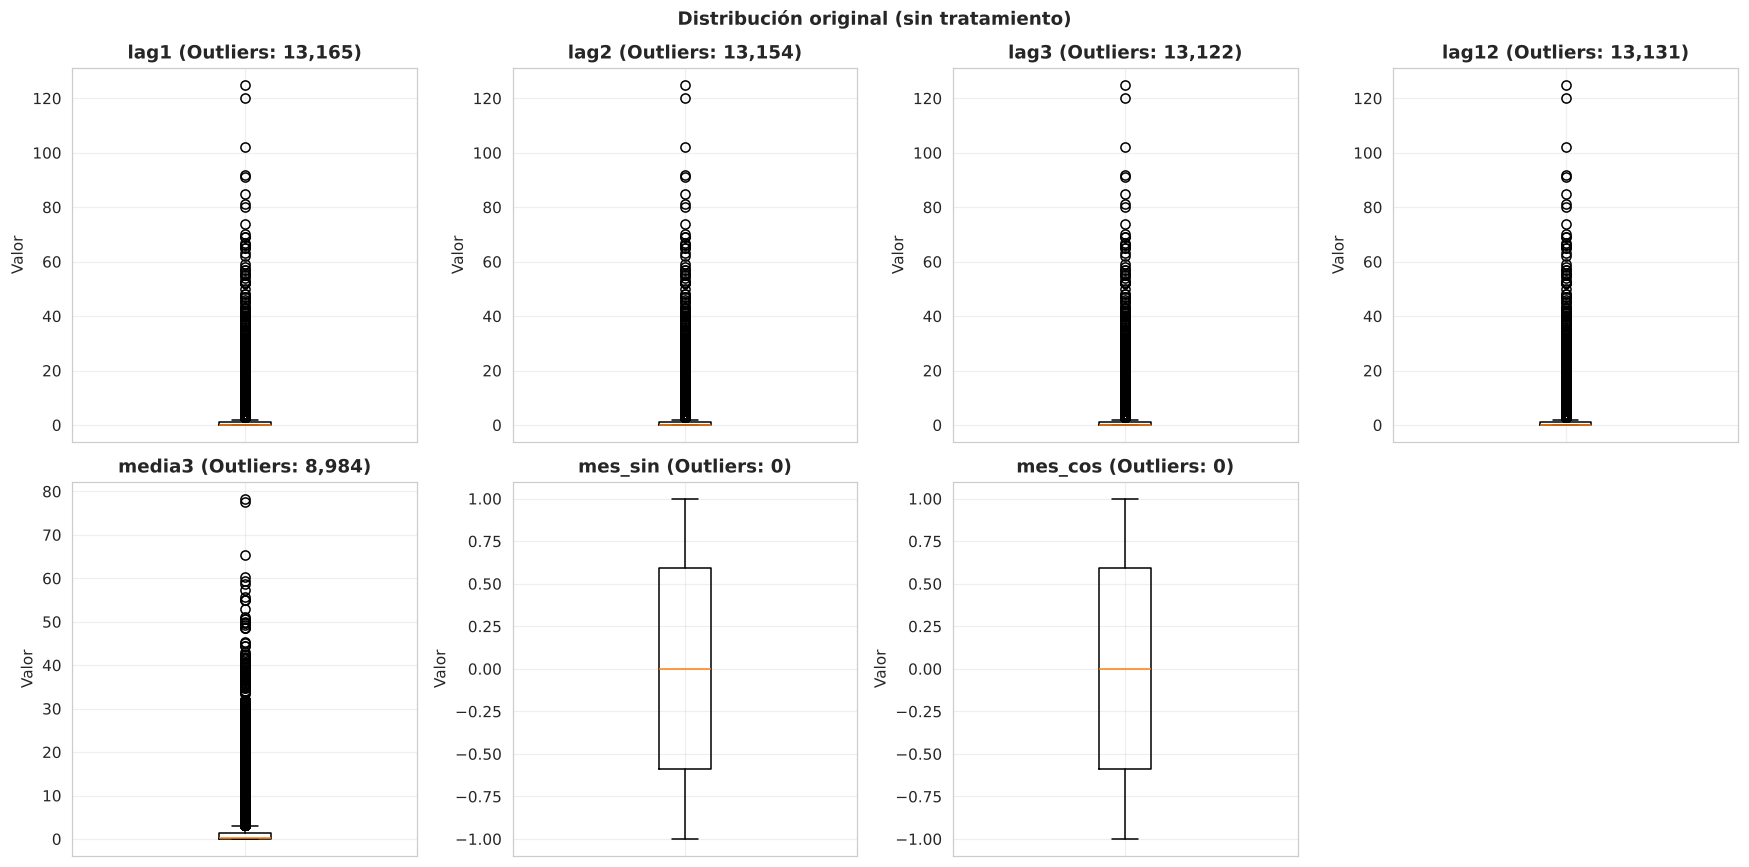

In [25]:
def plot_boxplots(df_, features, title="Boxplots"):
    # Boxplots con conteo de outliers por IQR (misma función de la guía)
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()
    for i, col in enumerate(features):
        axes[i].boxplot(df_[col], vert=True)
        q1, q3 = df_[col].quantile(0.25), df_[col].quantile(0.75)
        iqr = q3 - q1
        n_out = ((df_[col] < q1 - 1.5 * iqr) | (df_[col] > q3 + 1.5 * iqr)).sum()
        axes[i].set_title(f"{col} (Outliers: {n_out:,})", fontweight="bold")
        axes[i].set_ylabel("Valor")
        axes[i].set_xticklabels([])
        axes[i].grid(alpha=0.3)
    axes[len(features)].axis("off")
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()

plot_boxplots(Xc, FEATURES, "Distribución original (sin tratamiento)")
guardar("boxplots_antes")
plt.show()

### 7.3 ¿Los extremos son brotes o artefactos de registro?

In [25]:
# ¿Los valores extremos son brotes reales o podrían ser artefactos de registro (semana 1)?
top100 = panel_m.nlargest(100, "casos")
print("De los 100 mayores conteos distrito-mes, los que caen en enero:", int((top100["fecha_mes"].dt.month == 1).sum()))
print(top100[["distrito", "departamento", "fecha_mes", "casos"]].head(6).to_string(index=False))

alertas = panel_m.loc[panel_m["alerta"] == 1, "fecha_mes"].dt.month
print(f"\nMeses en alerta que caen en enero: {(alertas == 1).mean():.1%}  (enero es {1 / 12:.1%} de todos los meses)")

De los 100 mayores conteos distrito-mes, los que caen en enero: 42
  distrito departamento  fecha_mes  casos
  ECHARATE        CUSCO 2007-01-01    125
  ECHARATE        CUSCO 2006-01-01    120
  ECHARATE        CUSCO 2010-01-01    102
  ECHARATE        CUSCO 2012-01-01     92
SHAMBOYACU   SAN MARTIN 2011-03-01     91
SHAMBOYACU   SAN MARTIN 2011-04-01     85

Meses en alerta que caen en enero: 22.4%  (enero es 8.3% de todos los meses)



### Qué muestran los resultados

- **Z-score e IQR discrepan por un orden de magnitud.** El z-score marca cerca del 1,75 % de los meses, y el IQR entre 9,6 % y 14 %. La causa es la abundancia de ceros: Q1 = 0 y Q3 = 1, así que el límite superior del IQR queda en 2,5 casos y cualquier mes con 3 o más cuenta como atípico. El IQR está pensado para distribuciones continuas y aquí pierde sentido.
- **Los extremos son la variable de interés.** En la guía los outliers son ruido, aquí un brote es precisamente un mes con un valor extremo. Por eso concluimos que la distribución de datos es cero-inflada y de cola larga y no hay que eliminar estos datos.
- **Los extremos no son necesariamente todos brotes reales.** Entre los 100 mayores conteos distrito-mes, 42 caen en enero (los cuatro primeros son de Echarate, Cusco: 125, 120, 102 y 92 casos), y el 22,4 % de los meses en alerta es enero, frente al 8,3 % que representa enero del total de meses. Es coherente con la anomalía de la semana 1: parte de esos picos puede ser acumulación de registros a inicio de año y no un brote real.



## 8. Conclusiones

**Hallazgos**

1. El dataset es de **leishmaniosis cutánea**: 156 819 casos individuales entre 2000 y 2024, en 23 departamentos.
2. La serie anual tiene picos en 2007 y 2011 (≈ 9 500 casos), baja de forma gradual hasta 2019–2020 y se mantiene después entre 4 500 y 5 100. Con estos datos no se puede saber si la baja es menor transmisión o menor notificación.
3. Hay una **estacionalidad anual marcada y estable**: entre el 60 % y el 71 % de los casos de cada año (salvo 2020) se notifica en el primer semestre, y la autocorrelación a 12 meses es 0,79.
4. La **semana 1 es una anomalía de registro** (2,6 veces los casos de las semanas vecinas) que probablemente infla enero y los valores extremos.
5. Los casos están **muy concentrados**: el 10 % de los distritos reúne el 65 % de los casos.
6. A escala distrito-mes, el 60,9 % de las observaciones es cero y la asimetría es 8,7: la distribución es cero-inflada y de cola larga.
7. Los rezagos tienen faltantes **estructurales** (4,0 % en `lag12`): son los primeros meses de cada distrito, sin historia previa.
8. La definición provisional de alerta produce un desbalance de 20:1 en entrenamiento y de 28:1 en prueba.
9. El z-score marca ≈ 1,75 % de los meses como outliers y el IQR entre 9,6 % y 14 %. Los extremos son los brotes que se quiere predecir.

**Problemas de calidad detectados**

- `ubigeo` perdió el cero inicial en 56 057 registros (solo se corrigió el formato).
- `edad` mezcla años, meses y días y tiene 4 valores imposibles (marcados como nulos).
- `localcod` tiene 32 % de faltantes, `localidad` 5,6 % y `diresa` 6.
- 1 119 duplicados exactos y anomalía de la semana 1: señalados, no tratados.

**Decisiones para el modelado**

| Decisión | Elección |
|---|---|
| Resolución temporal | Mensual |
| Unidad espacial | Distrito con al menos 50 casos acumulados (435 distritos, 95,4 % de los casos) |
| Partición | Entrenamiento ≤ 2018 y prueba 2019–2024, nunca aleatoria |
| Variables | `lag1`, `lag2`, `lag3`, `lag12`, `media3`, `mes_sin`, `mes_cos` |
| Validación | Ventana deslizante hacia adelante |
| Baselines | Último valor observado y mismo mes del año anterior |
| Métricas de clasificación | Recall, precisión, F1 y área bajo la curva precisión-recall (no accuracy) |
| Sensibilidad | Repetir los modelos con y sin la semana 1 |
